In [1]:
%run ./dataManipulation.ipynb

In [2]:
import seaborn as sns
from scipy import stats

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, recall_score, precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

2024-03-18 16:41:45.822647: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

## Class Imbalance

,Value,Frequency,Percentage
Male,0,503,78.59375
Female,1,137,21.40625


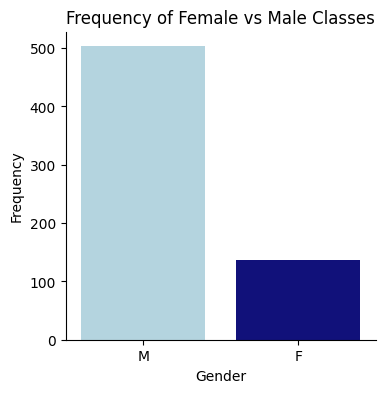

In [4]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0].astype(int)
# No of men vs no of women

valueCounts = pd.DataFrame(y).value_counts().reset_index()
valueCounts.columns = ['Value', 'Frequency']
valueCounts = valueCounts.rename(index={0: 'Male', 1: 'Female'})
totalClips = valueCounts['Frequency'].sum()
valueCounts['Percentage'] = (valueCounts['Frequency'] / totalClips) * 100
display(Markdown('## Class Imbalance'))
display(valueCounts)


array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
plt.figure(figsize=(4, 4))
sns.countplot(x='Gender',data=df,hue='Gender',palette=['lightblue', 'darkblue'])
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title('Frequency of Female vs Male Classes')
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.show()




## PCA

Pricipal component variance: [0.35845079 0.29290806]


'Relationship between original features (Big Five) and Principal Components:'

,PC1,PC2
Extraversion,0.602524,-0.157927
Agreeableness,-0.371915,-0.584500
Conscientiousness,0.370081,-0.533504
Neuroticism,0.487827,0.439006
Openness,0.351723,-0.395052


Amount of variance per principal component: [0.35845079 0.29290806 0.15350095 0.10301126 0.09212895]


<Figure size 640x480 with 0 Axes>

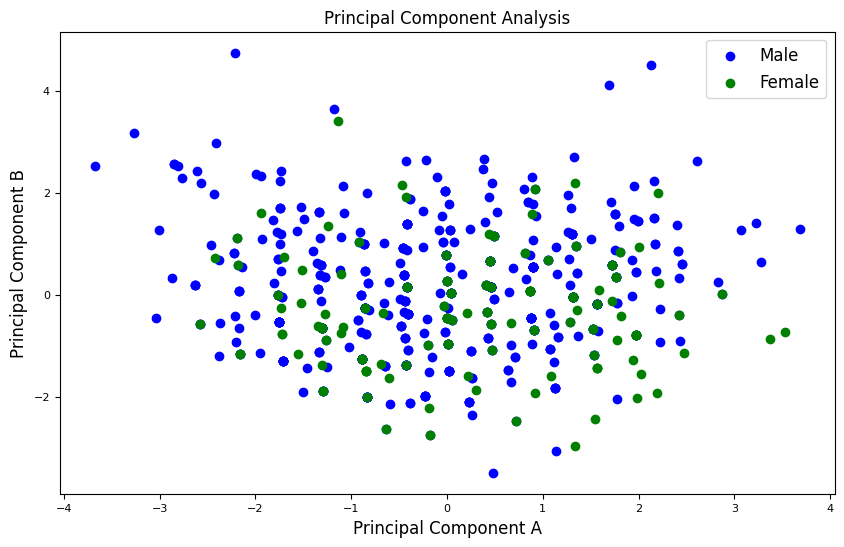

In [5]:
data = medianScoresPerClip()[:,1:]

labels = np.reshape(y, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[1:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)

x = finalDataset.loc[:, columns[1:6]].values
x = StandardScaler().fit_transform(x)

normalised = pd.DataFrame(x, columns=bigFive)

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
pcaDf = pd.DataFrame(data = princComp, columns = ['principal component 1', 'principal component 2'])

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT OF THE TWO
print('Pricipal component variance: {}'.format(pca.explained_variance_ratio_))

# Relationship between original features (Big Five) and Principal Components
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=bigFive)
display("Relationship between original features (Big Five) and Principal Components:", loadings)

# Two components result to 65% of variance while we need 4 to get 90%

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT
pcaAllComponents = PCA(n_components=5)
princComp = pcaAllComponents.fit_transform(x)
print('Amount of variance per principal component: {}'.format(pcaAllComponents.explained_variance_ratio_))


plt.figure()
plt.figure(figsize=(10,6))
plt.title("Principal Component Analysis",fontsize=12)
plt.xlabel('Principal Component A',fontsize=12)
plt.ylabel('Principal Component B',fontsize=12)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
targets = ['Male', 'Female']
colours = ['blue', 'green']
for target, colour in zip(targets,colours):
    i = finalDataset['Gender'] == target
    plt.scatter(pcaDf.loc[i, 'principal component 1']
               , pcaDf.loc[i, 'principal component 2'], c = colour)
plt.legend(targets,prop={'size': 12})


In [6]:
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
newX = np.concatenate((np.array(metadata)[:,0:2], X, y.reshape(-1, 1)), axis=1)
data = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender'])


## Before Hyperparameter tuning


In [7]:
# USING MANUAL HYPERPARAMETER TUNING - BASED ON K FOLDS 
# REPEATING IT A FINAL TIME AFTER SETTLING ON HYPERPARAMETERS

featureColumns = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
features = data[featureColumns]
target = data['Gender']
groups = data['speakerID']

# ALGORITHMS

logisticReg = LogisticRegression(class_weight='balanced')
randomForest = RandomForestClassifier(class_weight='balanced')
decisionTree=DecisionTreeClassifier(class_weight='balanced')
SVM = SVC(class_weight='balanced')
Kneightbors = KNeighborsClassifier()


n_splits = 10
kFold = StratifiedGroupKFold(n_splits=n_splits) 

def calculateResults(model, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    accuracy = []
    recall = []
    precision = []
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]


    fold_assignments = np.zeros_like(X['speakerID'])
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        accuracy.append(accuracy_score(y_te, prediction))
        recall.append(recall_score(y_te, prediction))
        precision.append(precision_score(y_te, prediction, zero_division=0.0))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
        
        
    result = pd.DataFrame({'F1 score': f1Scores, 'Accuracy score': accuracy, 'Precision score': precision, 'Recall score': recall})
    return (result, accuracy, confusionMatrixTotal)



In [8]:
algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]

f1Scores = []
accuracyValues = []
recallValues =[]
precisionValues = []
confusionMatrices =[]
listsOfAccuracies =[]
before = {}

for i in range (len(algorithms)):
    result_accuracy = calculateResults(algorithms[i], data, target)
    result = result_accuracy[0]
    confusionMatrices.append(result_accuracy[2])
    f1Scores.append(np.mean(result['F1 score']))
    accuracyValues.append(np.mean(result['Accuracy score']))
    recallValues.append(np.mean(result['Recall score']))
    precisionValues.append(np.mean(result['Precision score']))
    listsOfAccuracies.append(result_accuracy[1])

    before[i] = result


In [9]:

binomialTestResults = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatrices[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[p, accuracyValues[i],f1Scores[i], recallValues[i], precisionValues[i],confusionMatrices[i][0],result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])


binomialTestResults.rename(columns={0: 'prior probability', 1: 'accuracy', 2: 'f1 value',3: 'recall', 4: 'precision', 5: 'confusion matrix', 6: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

,prior probability,accuracy,f1 value,recall,precision,confusion matrix,Binomial test p value
Logistic Regression,0.663521,0.689063,0.479957,0.676923,0.373801,"[348, 155]",1.807214e-01
Random Forest,0.663521,0.682813,0.316041,0.344505,0.302644,"[390, 113]",3.155136e-01
Decision Tree,0.663521,0.637500,0.359802,0.469231,0.296781,"[344, 159]",1.675182e-01
SVM,0.663521,0.704688,0.450147,0.575824,0.377322,"[372, 131]",2.952793e-02
K neighbours,0.663521,0.798438,0.357881,0.264286,0.585476,"[475, 28]",6.192301e-14


## With Hyperparameter tuning
### GridSearch & loop

In [10]:
## GRID SEARCH HYPERPARAMETER TUNING USING gridSearch to find best params & k fold to get result

def calculateResultsGrid(modelName, model, parameters, X, y):
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    accuracy = []
    recall = []
    precision = []
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    
    fold_assignments = np.zeros_like(X['speakerID'])
    gridSearchCV = GridSearchCV(model, parameters, cv=StratifiedGroupKFold(n_splits=5), scoring='accuracy', n_jobs=-1, verbose=0)
    gridSearchCV.fit(features, target, groups=IDs['speakerID'])
    best_params = gridSearchCV.best_params_
    print(modelName,best_params)
    # display(pd.DataFrame(gridSearchCV.cv_results_))

    n_splits = 10
    kFold = StratifiedGroupKFold(n_splits=n_splits)     
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.set_params(**best_params)
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        
        f1Scores.append(f1_score(y_te, prediction))
        accuracy.append(accuracy_score(y_te, prediction))
        recall.append(recall_score(y_te, prediction))
        precision.append(precision_score(y_te, prediction,zero_division=0))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))

    result = pd.DataFrame({'F1 score': f1Scores, 'Accuracy score': accuracy, 'Precision score': precision, 'Recall score': recall})
    return (result, accuracy, confusionMatrixTotal)

In [72]:

models = {
'Logistic regression': (LogisticRegression(class_weight='balanced'), {'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky'],  'penalty': ['l2']}),
'Decision tree': (DecisionTreeClassifier(class_weight='balanced'), {'max_depth': [None, 10, 20, 30]}),
'Random forest': (RandomForestClassifier(class_weight='balanced'), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20, 30]}),
'SVM': (SVC(class_weight='balanced'), {'C': [0.1, 1, 5, 10], 'kernel': ['rbf','linear','poly'], 'degree': [2, 3, 5]}),
'K neighbours': (KNeighborsClassifier(), {'weights':['distance', 'uniform'], 'n_neighbors': [3, 5, 7, 9]})
}


allMeanScores = {'f1':[], 'accuracy':[], 'precision': [], 'recall':[]}
f1ScoresGrid = []
accuracyValuesGrid = []
recallValuesGrid =[]
precisionValuesGrid = []
confusionMatricesGrid =[]
listsOfAccuraciesGrid= []
modelNames = []
after = {}


for modelName, (model, parameters) in models.items():
    results = calculateResultsGrid(modelName, model, parameters, data, target)
    result = results[0]
    allMeanScores['f1'].append((np.mean(result['F1 score'])))
    allMeanScores['accuracy'].append((np.mean(result['Accuracy score'])))
    allMeanScores['precision'].append((np.mean(result['Precision score'])))
    allMeanScores['recall'].append((np.mean(result['Recall score'])))
    confusionMatricesGrid.append(results[2])
    f1ScoresGrid.append(result['F1 score'])
    accuracyValuesGrid.append(result['Accuracy score'])
    recallValuesGrid.append(result['Recall score'])
    precisionValuesGrid.append(result['Precision score'])
    listsOfAccuraciesGrid.append(results[1])
    modelNames.append(modelName)
    after[modelName] = result

AttributeError: 'dict' object has no attribute 'loc'

In [70]:

binomialTestResultsGrid = pd.DataFrame()
tTestResults = {'f1':[], 'accuracy':[],'precision':[], 'recall':[]}
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatricesGrid[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatricesGrid[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatricesGrid[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatricesGrid[i][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))

    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[p, allMeanScores['accuracy'][i],allMeanScores['f1'][i], allMeanScores['recall'][i], allMeanScores['precision'][i], confusionMatricesGrid[i][0],result.pvalue]])
    binomialTestResultsGrid = pd.concat([binomialTestResultsGrid,values])


    tTestResults['f1'].append(scipy.stats.ttest_ind(a=listsOfAccuracies[i], b=p, equal_var=True))
    tTestResults['accuracy'].append(scipy.stats.ttest_ind(a=f1ScoresGrid[i], b=p, equal_var=True))
    tTestResults['precision'].append(scipy.stats.ttest_ind(a=precisionValuesGrid[i], b=p, equal_var=True))
    tTestResults['recall'].append(scipy.stats.ttest_ind(a=recallValuesGrid[i], b=p, equal_var=True))

binomialTestResultsGrid.rename(columns={0: 'prior probability', 1: 'accuracy', 2: 'f1 value',3: 'recall', 4: 'precision', 5: 'confusion matrix', 6: 'Binomial test p value'}, inplace=True)
binomialTestResultsGrid.index = algorithmName
display(binomialTestResultsGrid)




,prior probability,accuracy,f1 value,recall,precision,confusion matrix,Binomial test p value
Logistic Regression,0.663521,0.689063,0.479957,0.676923,0.373801,"[348, 155]",1.807214e-01
Random Forest,0.663521,0.637500,0.359802,0.469231,0.296781,"[344, 159]",1.675182e-01
Decision Tree,0.663521,0.685937,0.322383,0.352198,0.310600,"[391, 112]",2.415556e-01
SVM,0.663521,0.765625,0.382703,0.342857,0.443810,"[443, 60]",2.306020e-08
K neighbours,0.663521,0.796875,0.305703,0.219231,0.611944,"[480, 23]",1.195554e-13


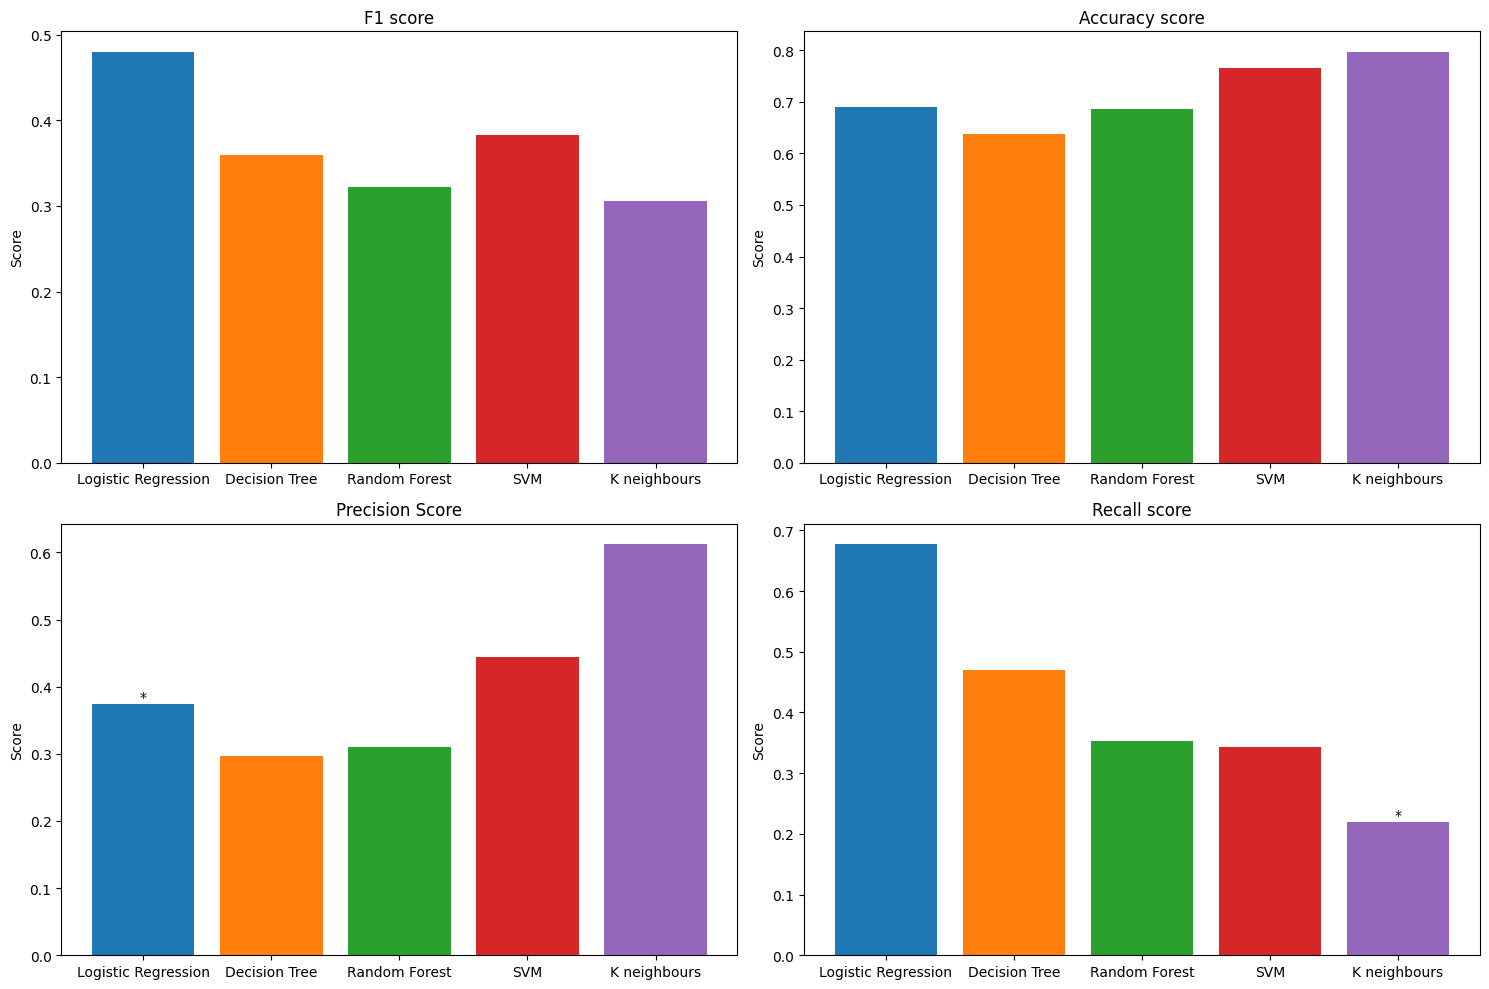

In [71]:
significance_levels = [[test.pvalue < 0.01 for test in model] for model in tTestResults.values()]

metrics = list(allMeanScores.keys()) #Performance metrics
metricTitles = ['F1 score', 'Accuracy score', 'Precision Score', 'Recall score']
models = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'SVM', 'K neighbours']

fig, axs = plt.subplots(2, 2, figsize=(15, 10))  
axs = axs.flatten()

for i, metric in enumerate(metrics):
    ax = axs[i]
    values = allMeanScores[metric]
    significance = significance_levels[i]
    bars = ax.bar(models, values, color=plt.cm.tab10(np.arange(len(models))))
    # Adding stars for significance of t tests
    for bar, p_value in zip(bars, significance):
        if p_value:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), '*', ha='center', va='bottom')
    ax.set_title(metricTitles[i])
    ax.set_ylabel('Score')
plt.tight_layout()
plt.show()